# 📂 6장 · 파일에서, 웹에서: 데이터 불러오기 (실습 노트북 v2)

『빅데이터분석 with 파이썬』 6장의 **05. 파이썬 실습**, **미니 프로젝트**, **연습문제**를 따라 하는 노트북입니다. 실습 번호는 책과 같습니다.

| 표시 | 뜻 | 실습 |
|---|---|---|
| ★ 필수 | 책에 코드와 결과가 모두 있음. 수업 시간에 함께 | 6-1 ~ 6-6 |
| 🧪 코랩 실습 | 책에는 문제만 있고, 코드와 결과는 이 노트북에 | ☆ 6-7 ~ 6-10, 6-3·6-6의 ❺ 그래프, 미니 프로젝트 1·2단계 |

**데이터**: 강의 자료 「6장_강의자료.zip」(에어코리아 서울 2025년 엑셀 12개, 기상청 서울 시간자료 CSV, 한국전력거래소 전력수요 CSV 5개, 연습 사이트). 아래 준비 셀이 책 깃허브 저장소에서 받아 풉니다.

코드 셀은 **위에서부터 차례로** 실행하십시오(`Shift + Enter`). 아래 셀은 위에서 만든 변수를 이어서 씁니다. 웹 실습(6-4~6-10)은 코랩 안에서 켠 연습 사이트에 접속하므로 바깥 사이트에 부담을 주지 않습니다.

## 0 · 준비

① 그래프의 한글이 깨지지 않게 **koreanize-matplotlib**를 설치합니다. ② 강의 자료를 받아 풉니다(📁 파일 창에 직접 올렸다면 받기는 건너뜁니다). ③ 판다스와 그래프 글꼴을 준비합니다.

In [1]:
!pip install -q koreanize-matplotlib

In [2]:
import os, urllib.request
if not os.path.exists("6장_강의자료.zip") and not os.path.exists("6장_강의자료"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/yeonu69/bigdata-python-book/main/ch06/data/" + "6%EC%9E%A5_%EA%B0%95%EC%9D%98%EC%9E%90%EB%A3%8C.zip", "6장_강의자료.zip")
if not os.path.exists("6장_강의자료"):
    !unzip -q -O utf-8 6장_강의자료.zip
print(sorted(os.listdir("6장_강의자료")))

['기상청_서울_시간자료_원본.csv', '에어코리아_서울_2025', '연습사이트', '전력수요']


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib            # 코랩: 한글 글꼴을 자동으로 설정
except ImportError:                        # 나눔고딕 파일이 이미 있는 컴퓨터
    import glob
    import matplotlib.font_manager as fm
    for f in glob.glob(os.path.expanduser("~/.fonts/Nanum*.ttf")):
        fm.fontManager.addfont(f)
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

## 05. 파이썬 실습: 파일 열두 개와 웹페이지 스물여덟 쪽

> **[이 실습에서 할 일] 실습 전에 미리 살펴보기**
>
> 데이터: 기상청 서울 날씨 CSV 하나(받은 그대로), 에어코리아 서울 2025년 엑셀 12개, 연습 사이트(목록 3쪽 + 측정소 25쪽).
>
> 도구: 파일은 판다스(read_csv, read_excel, concat), 웹은 requests(받기)와 뷰티풀수프(찾기). 코랩에 모두 들어 있습니다.
>
> 순서: 6-1~6-3은 파일 길, 6-4~6-6은 웹 길이고, 6-6 끝에서 두 길의 답을 맞춰 봅니다.


> **[분석 기법] 불러오기가 분석과 모델의 품질을 정한다**
>
> 데이터 분석과 머신러닝에는 "쓰레기를 넣으면 쓰레기가 나온다(Garbage In, Garbage Out)"는 말이 있습니다. 한글이 깨진 열, 빠진 달, 겹친 줄은 오류 없이 그대로 평균과 모델 속으로 들어갑니다. 그래서 불러오기의 목표는 "읽혔다"가 아니라 **"맞게 읽혔다"**입니다. 이 절의 실습은 모두 "읽기 → 확인 → 검산"의 세 박자로 끝납니다. 어떤 데이터를 받든 이 세 박자를 습관으로 삼으세요.

### [실습 예제 6-1 ★] 인코딩 오류를 만나고 고치기

기상청에서 받은 서울 날씨 CSV⁵⁾를 그대로 읽어 오류를 확인하고, 인코딩을 바꾸어 다시 읽으시오.

> **[이 실습에서 할 일] 흐름과 확인할 것**
>
> 흐름: ❶ 그대로 읽어 오류 보기 → ❷ 인코딩을 알려 주고 다시 읽기 → ❸ 바이트로 까닭 확인하기
>
> 배우는 기법: `read_csv(encoding=…)`, `try`/`except`, 글자와 바이트(`encode`, `hex`)
>
> 확인할 것: 오류 메시지의 첫 바이트, 다시 읽은 표의 크기 (24, 38)

**❶ 그대로 읽어 오류 보기**

In [4]:
import pandas as pd
DATA = "6장_강의자료"
PATH = DATA + "/기상청_서울_시간자료_원본.csv"
try:
    w = pd.read_csv(PATH)  # 아무것도 정하지 않으면 UTF-8로 읽는다
except UnicodeDecodeError as e:
    print("오류:", e)

오류: 'utf-8' codec can't decode byte 0xc1 in position 0: invalid start byte


- `import pandas as pd`: 판다스를 `pd`라는 짧은 이름으로 불러옵니다. 거의 모든 분석 코드의 첫 줄입니다.
- `DATA + "/…"`: 글자끼리 `+`로 이으면 파일 경로가 됩니다. 폴더 이름을 한 곳(`DATA`)에만 적어 두면, 폴더가 바뀌어도 한 줄만 고치면 됩니다.
- `try:` 아래가 실패하면 프로그램이 멈추지 않고 `except` 아래로 넘어가 오류 메시지 `e`를 보여 줍니다.

판다스는 기본으로 UTF-8을 가정합니다. 첫 바이트 `0xc1`은 UTF-8 규칙에 없는 시작이라 바로 실패했습니다. 이 `0xc1`이 다음 단계의 단서입니다.

> **[코드 읽기] try와 except: 실패를 예상하는 코드**
>
> `try:` 아래 코드를 해 보고, 그 안에서 `except` 뒤에 적은 종류의 오류가 나면 멈추지 않고 `except` 아래를 실행합니다. `as e`는 오류 내용을 변수 `e`에 담으라는 뜻입니다. 파일이 없을 때(`FileNotFoundError`), 숫자로 바꿀 수 없을 때(`ValueError`), 웹 요청이 실패할 때처럼 "실패할 수 있는 줄"에 씁니다. 다만 `except:`처럼 종류를 적지 않으면 모든 오류를 삼켜 버려 진짜 문제를 놓치므로, 잡을 오류의 이름을 꼭 적습니다.

**❷ 인코딩을 알려 주고 다시 읽기**

In [5]:
w = pd.read_csv(PATH, encoding="cp949")  # 한글 윈도의 옛 약속으로
print("크기:", w.shape)
print(w.iloc[:3, [1, 2, 3, 11]])

크기: (24, 38)


  지점명                일시  기온(°C)  습도(%)
0  서울  2026-10-16 01:00    16.9     74
1  서울  2026-10-16 02:00    16.3     77
2  서울  2026-10-16 03:00    16.7     79


- `encoding="cp949"`: 파일을 쓴 약속을 알려 줍니다. 우리나라 공공기관이나 오래된 회사 시스템이 내보낸 CSV는 CP949인 경우가 많습니다.
- `w.shape`: (행 수, 열 수)입니다. 한 시간이 한 줄이므로 하루 치 24행, 기상 항목 38열입니다.
- `w.iloc[:3, [1, 2, 3, 11]]`: "처음 세 줄, 1·2·3·11번째 열"을 번호로 골라 봅니다. 38열을 다 찍으면 화면이 넘치므로 몇 열만 봅니다.

> **[코드 읽기] iloc과 loc: 번호로 고를까, 이름으로 고를까**
>
> `표.iloc[행, 열]`은 **번호**(0부터)로, `표.loc[행, 열]`은 **이름**(줄 이름표와 열 이름)으로 고릅니다. `w.iloc[:3, 1]`은 "처음 세 줄의 1번 열", `w.loc[:, "기온(°C)"]`은 "모든 줄의 기온 열"입니다. `:`는 "전부", `:3`은 "0, 1, 2번"(3은 빠짐)입니다. 열 하나만 고를 때는 `w["기온(°C)"]`처럼 대괄호에 이름을 넣는 것이 가장 짧습니다. 열의 순서는 파일마다 바뀔 수 있으므로, 분석 코드에서는 번호보다 이름으로 고르는 편이 안전합니다.

**❸ 같은 글자, 다른 바이트**

In [6]:
for enc in ["utf-8", "cp949"]:
    b = "서울".encode(enc)  # 글자 → 바이트
    print(f"{enc:>6}: {len(b)}바이트", b.hex(" "))
print("파일 맨 앞 4바이트:", open(PATH, "rb").read(4).hex(" "))

 utf-8: 6바이트 ec 84 9c ec 9a b8
 cp949: 4바이트 bc ad bf ef
파일 맨 앞 4바이트: c1 f6 c1 a1


- `for enc in [...]`: 목록의 값을 하나씩 `enc`에 넣으며 아래 두 줄을 되풀이합니다.
- `.encode(enc)`: 글자를 그 약속의 바이트로 바꿉니다. `.hex(" ")`은 바이트를 16진수로, 빈칸을 사이에 두고 보여 줍니다.
- `open(PATH, "rb").read(4)`: 파일을 글자가 아닌 **바이트 그대로**(`"rb"` = read binary) 열어 맨 앞 4바이트를 읽습니다.

"서울"은 UTF-8로 6바이트, CP949로 4바이트입니다. 파일 맨 앞 `c1 f6 c1 a1`은 CP949로 "지점"이므로, 이 파일이 CP949로 쓰였다는 것을 바이트로 확인한 셈입니다.

> **[코드 읽기] f-문자열: 값을 글자 속에 끼워 넣기**
>
> 따옴표 앞에 `f`를 붙이면 `{ }` 안에 변수나 식을 넣을 수 있습니다. `f"{enc}: {len(b)}바이트"`는 "utf-8: 6바이트"가 됩니다. `{ }` 안의 `:` 뒤는 모양을 정합니다. `{enc:>6}`은 "6칸에 오른쪽 맞춤", `{x:,}`는 "천 단위 쉼표"(350,400), `{x:.1f}`는 "소수 첫째 자리까지"(18.1)입니다. 결과를 표처럼 줄 맞춰 찍을 때 자주 씁니다.

> **[코드 읽기] 인코딩을 모를 때의 순서**
>
> ① 그냥 읽는다(UTF-8). ② `UnicodeDecodeError`가 나면 `encoding="cp949"`. ③ 첫 열 이름 앞에 "﻿"가 붙으면 `encoding="utf-8-sig"`. ④ 그래도 글자가 이상하면 파일을 받은 곳의 안내문을 봅니다. `encoding_errors="ignore"`로 오류를 숨기는 것은 마지막 수단입니다. 글자가 깨진 채로 분석이 이어지기 때문입니다.

> **[분석 기법] 표의 기본: 행은 관측, 열은 변수**
>
> 판다스의 데이터프레임에서 **행**(줄) 하나는 관측 하나이고, **열** 하나는 관측마다 잰 **변수**(항목) 하나입니다. 날씨 표의 행은 "한 시간", 열은 기온·습도 같은 항목이고, 성적표라면 행은 학생, 열은 과목입니다. `shape`가 (24, 38)이면 관측 24개, 변수 38개입니다.
>
> 머신러닝에서는 같은 것을 다른 이름으로 부릅니다. 행은 **샘플**, 열은 **특성**(feature), 맞히려는 열은 **레이블**(target)입니다. 집값을 맞히는 문제라면 집 하나가 샘플, 넓이·층수·역까지 거리가 특성, 집값이 레이블입니다. 표를 받으면 "한 행이 무엇인가"부터 한 문장으로 말해 보세요. 이것이 모든 분석의 첫 질문입니다.

### [실습 예제 6-2 ★] 엑셀 한 파일의 신원 확인과 24시

2025년 1월 서울 엑셀을 읽어 크기, 자료형, 측정소 수를 확인하고, 측정일시의 24시를 다음 날 0시로 바꾸시오.

> **[이 실습에서 할 일] 흐름과 확인할 것**
>
> 흐름: ❶ 읽고 신원 확인(크기·자료형·값의 종류) → ❷ 24시를 몫과 나머지로 날짜·시각으로 바꾸기
>
> 배우는 기법: `read_excel`, `dtypes`, `value_counts`, `nunique`, `to_datetime`, `to_timedelta`
>
> 확인할 것: 29,760 = 측정소 40곳 × 31일 × 24시간이 맞는가

**❶ 읽고 크기 보기**

In [7]:
one = pd.read_excel(DATA + "/에어코리아_서울_2025/2025년 1월.xlsx")
print("크기:", one.shape)
print(one[["망", "측정소명", "측정일시", "PM25"]].head(3))

크기: (29760, 12)
      망 측정소명        측정일시  PM25
0  도시대기   중구  2025010101  12.0
1  도시대기   중구  2025010102  13.0
2  도시대기   중구  2025010103  12.0


- `pd.read_excel( )`: 엑셀 파일의 첫 시트를 표로 읽습니다. 다른 시트는 `sheet_name="시트이름"`으로 고릅니다.
- `one[[열 이름 목록]].head(3)`: 고른 열의 처음 세 줄만 봅니다. 대괄호를 두 겹 쓰면 열 여러 개를 골라 표로 받습니다. 새 표를 받으면 `shape`와 `head( )`로 "몇 줄, 몇 열, 어떻게 생겼나"부터 봅니다.

**❷ 자료형과 값의 종류 확인하기**

In [8]:
print(one.dtypes)  # 열마다 자료형
print(one["망"].value_counts().to_dict())  # 측정망마다 줄 수
print("측정소 수:", one["측정소명"].nunique())

지역           str
망            str
측정소코드      int64
측정소명         str
측정일시       int64
SO2      float64
CO       float64
O3       float64
NO2      float64
PM10     float64
PM25     float64
주소           str
dtype: object
{'도시대기': 18600, '도로변대기': 11160}
측정소 수: 40


- `one.dtypes`: 열마다 자료형입니다. 측정값은 `float64`(소수), 측정소코드·측정일시는 `int64`(정수), 이름은 글자(`str`)입니다.
- `value_counts( )`: 값마다 몇 줄인지 셉니다. `.to_dict( )`는 그 결과를 사전으로 바꾸어 한 줄에 보여 줍니다.
- `nunique( )`: 서로 다른 값이 몇 개인지 셉니다.

29,760 = 40곳 × 31일 × 24시간이므로 **한 측정소가 한 시간에 한 줄씩** 남긴 표입니다. 도시대기 25곳(18,600줄)과 도로변대기 15곳(11,160줄)이 섞여 있다는 것도 여기서 알게 됩니다.

> **[분석 기법] 자료형과 변수의 종류**
>
> 판다스는 열마다 **자료형**을 정합니다. 정수는 `int64`, 소수는 `float64`, 글자는 `object` 또는 `string`, 날짜·시각은 `datetime64`입니다. 이 장의 엑셀에서 측정값(PM25 등)은 `float64`, 측정소명·망은 글자, 측정소코드와 측정일시는 `int64`입니다.
>
> 자료형과 별개로 변수의 **종류**도 따져야 합니다. 크기를 견줄 수 있는 **수치형**(기온, 키, 매출)과 이름표 구실을 하는 **범주형**(측정소, 혈액형, 지역)입니다. 측정소코드 111121은 숫자로 적혀 있지만 범주형입니다. 코드의 평균은 아무 뜻이 없습니다. 우편번호, 학번, 전화번호도 마찬가지입니다.
>
> 머신러닝 모델은 대부분 숫자만 받으므로, 범주형 변수는 나중에 "범주마다 0/1 열 하나"(원-핫 인코딩) 같은 방법으로 바꾸어 넣습니다. 그래서 불러오자마자 `dtypes`를 보고 "숫자처럼 보이는 범주"와 "글자로 읽힌 숫자"를 찾아 두는 습관이 중요합니다.

**❸ 그대로 날짜로 바꾸면 실패한다**

In [9]:
try:
    pd.to_datetime(one["측정일시"].astype(str), format="%Y%m%d%H")
except ValueError as e:
    print("날짜로 바꾸지 못함:", str(e)[:60])

날짜로 바꾸지 못함: unconverted data remains when parsing with format "%Y%m%d%H"


- `.astype(str)`: 숫자 2025010101을 글자 "2025010101"로 바꿉니다. `to_datetime`은 글자를 읽어 날짜로 바꾸기 때문입니다.
- `format="%Y%m%d%H"`: "연(4자리) 월 일 시(각 2자리)"의 모양을 알려 줍니다. `%H`는 00~23만 받으므로, 24시가 나오는 순간 실패합니다.

**❹ 몫과 나머지로 바꾸기 (식 6-6)**

In [10]:
day = pd.to_datetime((one["측정일시"] // 100).astype(str), format="%Y%m%d")
one["일시"] = day + pd.to_timedelta(one["측정일시"] % 100, unit="h")
print(one[["측정일시", "일시"]].iloc[22:26])

          측정일시                  일시
22  2025010123 2025-01-01 23:00:00
23  2025010124 2025-01-02 00:00:00
24  2025010201 2025-01-02 01:00:00
25  2025010202 2025-01-02 02:00:00


- `one["측정일시"] // 100`: 몫, 곧 앞 8자리(날짜)입니다. 열 전체에 한꺼번에 계산됩니다.
- `% 100`: 나머지, 곧 뒤 2자리(시)입니다.
- `pd.to_timedelta(값, unit="h")`: "몇 시간"이라는 **시간 길이**입니다. 날짜(0시)에 더하면 시각이 되고, 24시간을 더하면 다음 날 0시가 됩니다.
- `one["일시"] = …`: 계산 결과를 새 열로 붙입니다. 원래 열은 그대로 남겨 두어 나중에 검산할 수 있게 합니다.

2025010124는 1월 2일 0시가 되었습니다. 22~25번 줄을 고른 것은 첫 측정소의 하루가 바뀌는 자리를 보기 위해서입니다.

> **[분석 기법] 날짜·시각을 자료형으로 바꾸는 까닭**
>
> 2025010124 같은 숫자나 "2025-01-01" 같은 글자는 사람에게는 날짜지만, 컴퓨터에게는 그냥 수와 글자입니다. `pd.to_datetime( )`으로 `datetime64` 자료형으로 바꾸어야 세 가지가 됩니다.
>
> ① **시간 순 정렬과 간격 계산**: 빼면 시간 길이(`timedelta`)가 나오고, `diff( )`로 이웃한 줄의 간격을 셉니다(미니 프로젝트의 한 시간 간격 검산). ② **부분 꺼내기**: `.dt.month`, `.dt.hour`, `.dt.dayofweek`로 달·시·요일을 꺼냅니다. ③ **기간으로 묶기**: 하루 평균, 달 평균을 쉽게 냅니다.
>
> 머신러닝에서도 날짜에서 꺼낸 "시", "요일", "주말인가"가 좋은 특성이 됩니다. 전력수요, 매장 손님 수, 교통량처럼 시간에 따라 되풀이되는 데이터라면 더욱 그렇습니다.

### [실습 예제 6-3 ★] 엑셀 12개를 한 표로

2025년 서울 파일 12개를 찾아 달 순서로 세우고, 하나로 합친 뒤 행 수를 검산하시오.

> **[이 실습에서 할 일] 흐름과 확인할 것**
>
> 흐름: ❶ 파일 찾고 달 순서로 세우기 → ❷ 출처를 붙이며 읽고 합치기 → ❸ 행 수 검산 → ❹ 달 평균 그래프
>
> 배우는 기법: `glob`, `sorted(key=…)`, 정규 표현식, `concat`, `groupby`
>
> 확인할 것: 빠진 달이 없는가, 행 수가 부분의 합·기대 행 수와 같은가

**❶ 파일 찾기**

In [11]:
import glob, os, re
files = glob.glob(DATA + "/에어코리아_서울_2025/*.xlsx")
print("파일 수:", len(files))
print("글자 순서:", [os.path.basename(f) for f in sorted(files)][:4])

파일 수: 12
글자 순서: ['2025년 10월.xlsx', '2025년 11월.xlsx', '2025년 12월.xlsx', '2025년 1월.xlsx']


- `glob.glob( )`: `*`(아무 글자) 자리에 맞는 파일 이름을 모두 찾아 목록으로 돌려줍니다. 순서는 정해져 있지 않습니다.
- `os.path.basename(f)`: 긴 경로에서 파일 이름만 꺼냅니다.
- `sorted(files)`: 글자 순서로 줄 세웁니다. "1"(숫자)이 "월"(한글)보다 앞이므로 10월·11월·12월이 1월보다 앞에 섭니다(3.2절).

**❷ 달 순서로 세우고 빠진 달 찾기**

In [12]:
def month_of(path):  # 이름에서 '숫자+월'의 숫자만
    return int(re.search(r"(\d+)월", path).group(1))
files = sorted(files, key=month_of)
print("달 순서:", [os.path.basename(f) for f in files][:4])
print("빠진 달:", sorted(set(range(1, 13)) - {month_of(f) for f in files}))

달 순서: ['2025년 1월.xlsx', '2025년 2월.xlsx', '2025년 3월.xlsx', '2025년 4월.xlsx']
빠진 달: []


- `def month_of(path):`: 파일 경로를 받아 달 숫자를 돌려주는 함수를 만듭니다. `re.search(r"(\d+)월", …)`은 "숫자 한 개 이상 + 월"을 찾고, `.group(1)`은 괄호 안(숫자)만 꺼냅니다.
- `sorted(files, key=month_of)`: 파일마다 `month_of( )`를 불러 그 값(1~12)으로 줄 세웁니다.
- 마지막 줄: `set(range(1, 13))`은 1~12의 집합, `{…}`는 실제 있는 달의 집합입니다. 집합의 뺄셈이 "없는 달"입니다. 빈 목록 `[]`이면 열두 달이 모두 있습니다.

> **[코드 읽기] 함수 만들기: def와 return**
>
> `def 이름(받을 값):` 아래에 들여 쓴 줄들이 함수의 몸입니다. `return 값`은 계산한 값을 돌려주고 함수를 끝냅니다. 같은 계산을 여러 번 쓸 때(파일 12개에서 달 꺼내기), 또는 `sorted(key=…)`처럼 다른 함수에 "계산 방법"을 넘겨줄 때 만듭니다. 함수 이름은 하는 일을 드러내게 짓습니다(`month_of`, `get_soup`).

> **[코드 읽기] sorted(목록, key=함수)**
>
> `sorted`는 값 자체가 아니라 **key 함수가 돌려준 값**으로 줄 세웁니다. 파일 이름 대신 달 숫자로, 학생 이름 대신 점수로(`key=lambda s: s["점수"]`), 글자 대신 길이로(`key=len`) 세울 수 있습니다. 큰 것부터 세우려면 `reverse=True`를 더합니다. 파일을 합치기 전에 순서를 정해 두면, 합친 표의 줄 순서와 출처를 사람이 읽을 수 있습니다.

**❸ 읽으며 출처를 표시하고 합치기**

In [13]:
parts = []
for f in files:
    t = pd.read_excel(f)
    t["파일"] = os.path.basename(f)  # 어느 파일에서 왔는지
    parts.append(t)
print("열 이름이 모두 같은가:", all(list(p.columns) == list(parts[0].columns) for p in parts))
air = pd.concat(parts, ignore_index=True)  # 위아래로 이어 붙이기
print("합친 크기:", air.shape)

열 이름이 모두 같은가: True
합친 크기: (350400, 13)


- `parts = []` … `parts.append(t)`: 빈 목록을 만들고 표를 하나씩 담습니다. 파일 12개를 읽는 데 엑셀이라 1분 남짓 걸립니다.
- `t["파일"] = …`: 줄마다 어느 파일에서 왔는지 적어 둡니다. 나중에 이상한 줄을 찾으면 원본 파일로 바로 거슬러 갈 수 있습니다.
- `all(…)`: 괄호 안의 판단이 모두 True일 때만 True입니다. 열 이름이 하나라도 다르면 `concat`이 오류 없이 빈칸 가득한 열을 만들기 때문에 미리 확인합니다.
- `pd.concat(parts, ignore_index=True)`: 표 목록을 위아래로 잇고, 줄 번호를 0부터 새로 매깁니다.

**❹ 검산하기 (식 6-4, 6-5)**

In [14]:
print("행 수 검산:", sum(len(p) for p in parts), "=", len(air))
air["달"] = air["측정일시"] // 10000 % 100  # 2025013124 → 1
days = air.groupby("달")["측정일시"].apply(lambda s: (s // 100).nunique())
check = pd.DataFrame({"행": air.groupby("달").size(),
                      "기대": days * 24 * air["측정소코드"].nunique()})
print(check.T.iloc[:, :6])  # 1~6월만 가로로
print("열두 달 모두 같은가:", (check["행"] == check["기대"]).all())

행 수 검산: 350400 = 350400
달       1      2      3      4      5      6
행   29760  26880  29760  28800  29760  28800
기대  29760  26880  29760  28800  29760  28800
열두 달 모두 같은가: True


- 첫 줄: 부분의 합(식 6-4)과 합친 표의 행 수를 견줍니다.
- `// 10000 % 100`: 끝 네 자리(일·시)를 떼고(몫), 남은 수의 끝 두 자리(나머지), 곧 달입니다.
- `days`: 달마다 서로 다른 날짜(앞 8자리) 수입니다. 1월은 31, 2월은 28입니다.
- `check`: 달마다 실제 행 수와 기대 행 수(날 수 × 24 × 측정소 수, 식 6-5)를 나란히 둔 표입니다. `.T`는 행과 열을 바꾸어 가로로 보여 주고, `.iloc[:, :6]`은 그 가운데 1~6월 열만 고릅니다. 마지막 줄은 열두 달을 한꺼번에 견줍니다.

열두 달 모두 실제와 기대가 같습니다. 부분의 합만 맞추면 파일을 두 번 읽은 실수는 잡지 못합니다. 기대 행 수까지 맞아야 "빠진 것도 겹친 것도 없다"고 말할 수 있습니다.

> **[코드 읽기] lambda: 이름 없는 한 줄 함수**
>
> `lambda s: (s // 100).nunique()`는 "s를 받아 (s // 100)의 서로 다른 값 수를 돌려주는 함수"입니다. `def`로 따로 만들 만큼 길지 않은 계산을 `apply`, `sorted(key=…)`, `groupby(…).apply` 안에 바로 적을 때 씁니다. 여기서는 달마다 묶인 측정일시 묶음이 차례로 `s`에 들어옵니다.

> **[코드 읽기] 짧게 쓰는 목록 만들기: 컴프리헨션**
>
> `[os.path.basename(f) for f in files]`는 "files의 f마다 basename(f)를 계산해 목록으로"라는 뜻입니다. 네 줄짜리 for 반복(빈 목록 만들기 → 돌기 → 계산 → append)을 한 줄로 줄인 것입니다. 괄호를 `{ }`로 바꾸면 집합, `sum(len(p) for p in parts)`처럼 함수 안에 바로 쓰면 하나씩 더하는 계산이 됩니다.

**❺ 달 평균을 그래프로 보기**  🧪 *(코랩 실습: 책에는 그림만)*

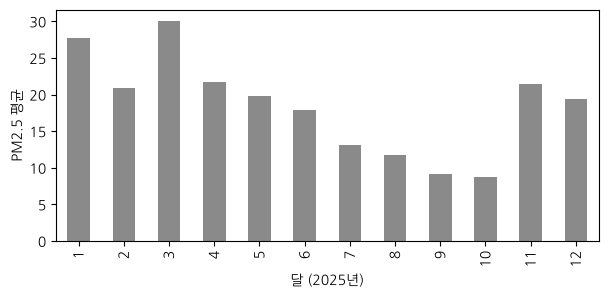

In [15]:
import matplotlib.pyplot as plt
city = air[air["망"] == "도시대기"]  # 조건에 맞는 줄만
city.groupby("달")["PM25"].mean().plot.bar(color="#8a8a8a", figsize=(7, 3))
plt.xlabel("달 (2025년)"); plt.ylabel("PM2.5 평균"); plt.show()

- `air[조건]`: 조건이 True인 줄만 남깁니다(**불리언 인덱싱**). 도로변 측정소는 차가 다니는 길가의 공기를 재므로 성격이 다릅니다. 생활 공간을 대표하고, 6-6에서 웹으로 모을 25곳과 같은 도시대기만 골랐습니다.
- `groupby("달")["PM25"].mean()`: "달마다 PM25 평균"입니다. 결과에 `.plot.bar( )`를 붙이면 바로 막대그래프가 됩니다.


PM2.5는 3월이 가장 높고 9~10월이 가장 낮습니다. 왜 그런지는 이 표만으로는 알 수 없으므로, 보고서에는 "무엇이 보였다"까지만 씁니다.

> **[코드 읽기] 여러 파일 합치기의 기본 틀**
>
> "찾기(`glob`) → 순서 정하기(`sorted(key=…)`) → 출처 열 붙이며 읽기 → `concat` → 검산"은 월별 매출, 반별 성적표처럼 **여러 파일로 나뉜 모든 데이터**에 그대로 씁니다. 합치기 전에 열 이름이 모두 같은지도 확인합니다. `r"(\d+)월"`은 **정규 표현식**(글자 모양을 적는 식)으로 "숫자 하나 이상 + 월"에서 숫자만 꺼냅니다. `\d`는 숫자 한 개, `+`는 "하나 이상", `( )`는 "이 부분만 꺼내기"입니다.

> **[분석 기법] 묶어서 요약하기: groupby**
>
> `groupby`는 **나누고(split) → 계산하고(apply) → 합치는(combine)** 세 걸음을 한 줄로 합니다. `air.groupby("달")["PM25"].mean()`은 ① 표를 달마다 12묶음으로 나누고, ② 묶음마다 PM25 평균을 내고, ③ 달 12개와 평균 12개를 한 표로 모읍니다.
>
> 반별 평균 점수(`groupby("반")["점수"].mean()`), 지점별 매출 합계(`groupby("지점")["매출"].sum()`), 요일별 손님 수처럼 "무엇마다 얼마"를 묻는 질문은 거의 모두 groupby입니다. 계산은 `mean`, `sum`, `size`(줄 수), `nunique`(서로 다른 값 수), `max` 등으로 바꿔 끼웁니다. 묶는 열을 둘로 하면(`groupby(["측정소코드", "달"])`) "측정소·달마다"가 됩니다.

> **[분석 기법] 기술통계로 첫인상 보기: describe**
>
> `air["PM25"].describe()`는 숫자 열을 여덟 개의 수로 요약합니다. 이 장의 표에서는 개수 339,756, 평균 18.1, 표준편차 14.7, 최솟값 1, 사분위수 8·14·24, 최댓값 427입니다.
>
> 읽는 법은 세 가지입니다. ① **개수**가 전체 행 수(350,400)보다 적으면 그만큼 빈칸입니다. ② **평균(18.1)이 중앙값(50%, 14)보다 크면** 큰 값 몇 개가 평균을 끌어올린, 오른쪽 꼬리가 긴 분포입니다. 소득, 집값도 이런 모양입니다. ③ **최댓값 427**처럼 다른 값과 동떨어진 수는 **이상값** 후보입니다. 측정 오류인지, 황사 같은 실제 사건인지 확인하고 나서 지울지 정합니다.
>
> 새 데이터를 받으면 `describe()` 한 줄부터 실행하세요. 머신러닝 전처리(값의 크기 맞추기, 이상값 다루기)도 이 숫자들을 보고 정합니다.

### [실습 예제 6-4 ★] 요청과 응답, 그리고 robots.txt

연습 사이트를 켜고 목록 1쪽을 요청하시오. 기본 User-Agent와 직접 정한 User-Agent로 상태 코드를 견주고, robots.txt로 가져가도 되는 경로를 확인하시오.

> **[이 실습에서 할 일] 흐름과 확인할 것**
>
> 흐름: ❶ 이름 없이, 이름 밝히고 요청해 상태 코드 견주기 → ❷ robots.txt로 가져가도 되는 곳 확인
>
> 배우는 기법: `requests.get(headers=…)`, `status_code`, `robotparser`
>
> 확인할 것: 403과 200의 차이, /admin/이 막혀 있는가, 쉬는 시간 1초

**❶ 연습 사이트 켜기**

In [16]:
import subprocess, sys, time, requests
server = subprocess.Popen([sys.executable, "serve.py", "8000"],
                          cwd=DATA + "/연습사이트")  # 코랩 안에서 웹 서버 켜기
time.sleep(1)
BASE = "http://localhost:8000"

공기 기록 연습장: http://localhost:8000/


- `subprocess.Popen([...])`: 파이썬 프로그램 하나(`serve.py`)를 따로 띄웁니다. 실습이 끝날 때까지 뒤에서 웹 서버로 돌아갑니다.
- `localhost`: "지금 이 컴퓨터(코랩)"라는 뜻입니다. 8000은 그 컴퓨터 안의 문 번호(포트)입니다.
- `time.sleep(1)`: 서버가 켜질 때까지 1초 기다립니다.

실제 사이트를 쓰지 않는 까닭은 두 가지입니다. 실습 때문에 남의 서버에 부담을 주지 않고, 사이트가 바뀌어도 이 책의 코드가 그대로 돌아가게 하려는 것입니다.

**❷ 이름 없이, 그리고 이름을 밝히고 요청하기**

In [17]:
r = requests.get(BASE + "/list/1.html")
print("상태 코드:", r.status_code)
HEAD = {"User-Agent": "data-class-bot/1.0 (book ch6 practice)"}  # 영문만
r = requests.get(BASE + "/list/1.html", headers=HEAD)
print("상태 코드:", r.status_code, "|", len(r.text), "글자")
print(r.text[:120])

상태 코드: 403
상태 코드: 200 | 1836 글자
<!doctype html>
<html lang="ko">
<head>
<meta charset="utf-8">
<title>측정소 목록 1쪽 | 공기 기록 연습장</title>
<link rel="styleshee


- `requests.get(주소)`: 주소로 요청을 보내고 응답을 `r`에 받습니다. `r.status_code`는 상태 코드, `r.text`는 받은 HTML 글자입니다.
- `headers=HEAD`: 요청에 머리글을 붙입니다. 사전 `{"이름": "값"}` 모양이고, User-Agent에는 누구인지와 목적을 **영문으로** 적습니다(한글을 넣으면 `UnicodeEncodeError`).
- `r.text[:120]`: 받은 글자의 처음 120자를 봅니다. 브라우저가 그려 주던 표가 사실은 이런 태그 글자입니다.

기본 이름(`python-requests/…`)으로는 403(거절), 이름과 목적을 밝히자 200과 HTML 1,836글자를 받았습니다. 이 사이트는 이름을 밝히지 않은 로봇을 거절하도록 만들어 두었습니다. 실제 사이트도 비슷한 규칙을 두는 곳이 많습니다.

> **[코드 읽기] 사전(dict): 이름표가 붙은 값**
>
> `{"User-Agent": "data-class-bot/1.0"}`처럼 `{열쇠: 값}`을 쉼표로 늘어놓은 것이 **사전**입니다. `HEAD["User-Agent"]`로 값을 꺼내고, `HEAD["From"] = "me@example.com"`처럼 새 열쇠를 더합니다. 순서로 꺼내는 목록(`[…]`)과 달리 이름으로 꺼냅니다. 요청 머리글, JSON 응답, 표의 한 줄(`{"구": "중구", "코드": "111121"}`)이 모두 사전 모양이라 이 장에서 계속 나옵니다.

**❸ robots.txt에 묻기**

In [18]:
from urllib import robotparser
rp = robotparser.RobotFileParser(BASE + "/robots.txt")
rp.read()
for path in ["/list/1.html", "/station/111121.html", "/admin/index.html"]:
    print(f"{path:22} 가져가도 되나:", rp.can_fetch(HEAD["User-Agent"], BASE + path))
print("요청 사이에 쉴 시간:", rp.crawl_delay("*"), "초")

/list/1.html           가져가도 되나: True
/station/111121.html   가져가도 되나: True
/admin/index.html      가져가도 되나: False
요청 사이에 쉴 시간: 1 초


- `RobotFileParser(주소)` → `.read( )`: robots.txt를 받아 읽습니다.
- `can_fetch(이름, 주소)`: "이 로봇이 이 주소를 가져가도 되나"에 True·False로 답합니다.
- `crawl_delay("*")`: 모든 로봇(`*`)에게 정한 쉬는 시간(초)입니다.

robots.txt는 /admin/만 막고 1초씩 쉬라고 합니다. 다음 실습부터 이 두 가지를 그대로 지킵니다.

### [실습 예제 6-5 ★] 뷰티풀수프로 표 한 쪽 읽기

목록 1쪽을 파싱해 측정소 표를 데이터프레임으로 만들고, "다음" 링크를 찾으시오.

> **[이 실습에서 할 일] 흐름과 확인할 것**
>
> 흐름: ❶ HTML 글자를 나무로 만들고 줄 찾기 → ❷ 줄마다 칸을 꺼내 사전 목록 → 데이터프레임
>
> 배우는 기법: `BeautifulSoup`, `find`/`find_all`, `.text`, `a["href"]`, `pd.DataFrame(사전 목록)`
>
> 확인할 것: 줄 수가 10인가, "다음" 링크가 있는가

**❶ 나무 만들고 표 찾기**

In [19]:
from bs4 import BeautifulSoup
soup = BeautifulSoup(r.text, "html.parser")  # 글자 → 나무
table = soup.find("table", class_="stations")
print([th.text for th in table.find_all("th")])  # 머리줄 칸들
rows = table.find("tbody").find_all("tr")
print("줄 수:", len(rows))

['구', '측정소', '코드']
줄 수: 10


- `BeautifulSoup(글자, "html.parser")`: HTML 글자를 태그의 나무로 바꿉니다(**파싱**). 이제 "표 안의 줄"처럼 찾을 수 있습니다.
- `find("table", class_="stations")`: class가 stations인 **첫** 표 하나. `class`는 파이썬이 이미 쓰는 낱말이라 `class_`로 씁니다.
- `[th.text for th in …]`: 머리줄 칸(`th`)마다 태그를 뺀 글자만 꺼냅니다. 표의 열이 구·측정소·코드인지 확인했습니다.
- `find("tbody").find_all("tr")`: 몸통(`tbody`) 안의 **모든** 줄. 머리줄(`thead`)은 빠집니다.

**❷ 줄마다 칸 꺼내기**

In [20]:
recs = []
for tr in rows:
    td = tr.find_all("td")  # 한 줄의 칸 세 개
    a = td[1].find("a")  # 둘째 칸의 링크
    recs.append({"구": td[0].text, "측정소": a.text, "코드": td[2].text, "링크": a["href"]})
page1 = pd.DataFrame(recs)
print(page1.head(3))

     구  측정소      코드                      링크
0   중구   중구  111121  ../station/111121.html
1  종로구  종로구  111123  ../station/111123.html
2  용산구  용산구  111131  ../station/111131.html


- `td[0]`, `td[1]`: 칸 목록의 0번째, 1번째입니다. 파이썬은 0부터 셉니다.
- `a.text`는 링크 글자, `a["href"]`는 링크 주소입니다. 태그의 속성은 사전에서 꺼내듯 꺼냅니다.
- `pd.DataFrame(사전 목록)`: 사전 하나가 한 줄, 열쇠가 열 이름이 됩니다. 웹에서 모은 값을 표로 만드는 가장 흔한 방법입니다.

**❸ "다음" 링크 찾기**

In [21]:
nxt = soup.find("a", class_="next")
print("다음 쪽 링크:", nxt["href"] if nxt else "없음")

다음 쪽 링크: 2.html


- `nxt["href"] if nxt else "없음"`: 찾았으면 주소를, 못 찾았으면(`None`) "없음"을 씁니다. 마지막 쪽에는 "다음" 링크가 없으므로 이렇게 확인하는 습관이 필요합니다.

한 쪽에 10줄이 있고, 링크 `../station/111121.html`은 "지금 페이지에서 한 칸 위로 올라가서 station 폴더로"라는 **상대 주소**입니다. 다음 쪽은 `2.html`입니다.

> **[코드 읽기] 표를 찾는 열쇠 고르기**
>
> 표를 오른쪽 단추로 누르고 "검사"(F12)를 고르면 태그와 class가 보입니다. id(`find(id="daily")`)가 가장 확실하고, 다음이 class, 마지막이 "몇 번째 표"(`find_all("table")[1]`)입니다. 찾은 뒤에는 `len(rows)`로 0줄이 아닌지 확인합니다. 사이트가 모양을 바꾸면 열쇠가 맞지 않아 0줄이 되기 때문입니다.

> **[분석 기법] 정형·반정형·비정형 데이터**
>
> 데이터는 모양에 따라 셋으로 나뉩니다. **정형 데이터**는 행과 열이 정해진 표입니다(CSV, 엑셀, 데이터베이스). **반정형 데이터**는 표는 아니지만 태그나 이름표로 구조를 적어 둔 것입니다(HTML, JSON, XML). **비정형 데이터**는 정해진 구조가 없는 글, 사진, 소리, 영상입니다.
>
> 이 장에서 한 일은 반정형 데이터(HTML, JSON)를 정형 데이터(데이터프레임)로 바꾸는 일입니다. 회귀·분류·군집 같은 대부분의 머신러닝 모델이 정형 표를 입력으로 받기 때문입니다. 글이나 사진도 결국 숫자 표(단어 빈도, 픽셀 값)로 바꾸어 모델에 넣습니다.

### [실습 예제 6-6 ★] 여러 쪽을 돌며 모으고, 파일과 맞추기

"다음" 링크가 없을 때까지 목록을 넘기며 측정소 25곳을 모으고, 측정소 페이지마다 달 평균 표를 읽어 [실습 예제 6-3]의 파일 결과와 맞추시오.

> **[이 실습에서 할 일] 흐름과 확인할 것**
>
> 흐름: ❶ 예의 바른 요청 함수 → ❷ "다음"을 따라 목록 넘기기 → ❸ 측정소 페이지 돌기 → ❹ 파일 길과 맞추기 → ❺ 구별 그래프
>
> 배우는 기법: 함수 만들기, `while`, `urljoin`, `itertuples`, `to_numeric(errors="coerce")`, `merge`
>
> 확인할 것: 측정소 25곳, 표 300칸, 파일 길과 같은 칸 수

**❶ 예의 바른 요청 함수 만들기**

In [22]:
from urllib.parse import urljoin
def get_soup(url):
    time.sleep(rp.crawl_delay("*"))  # robots.txt대로 1초 쉬고
    res = requests.get(url, headers=HEAD, timeout=10)  # 10초 넘으면 포기
    res.raise_for_status()  # 200이 아니면 여기서 멈춘다
    return BeautifulSoup(res.text, "html.parser")

- `time.sleep(…)`: 요청마다 robots.txt가 정한 1초를 쉽니다.
- `timeout=10`: 서버가 10초 안에 답하지 않으면 기다리지 않고 오류를 냅니다. 없으면 끝없이 기다릴 수 있습니다.
- `raise_for_status( )`: 상태 코드가 400·500번대면 오류를 일으켜 멈춥니다. 403이나 404를 받고도 모르는 채 빈 표를 모으는 일을 막습니다.

쉬기·이름 밝히기·실패하면 멈추기를 함수 하나에 묶어 두면, 이 함수만 쓰는 한 예절이 저절로 지켜집니다.

> **[코드 읽기] 웹 요청이 실패할 때**
>
> 웹은 파일보다 실패가 잦습니다. 서버가 느리거나(시간 초과), 주소가 바뀌었거나(404), 너무 자주 왔다고 거절하거나(429, 403), 서버 안에서 오류가 납니다(500번대). 실제 수집 코드는 `try: … except requests.exceptions.RequestException as e:`로 실패를 잡아 **어느 주소에서 왜 실패했는지 기록하고**, 잠시 쉬었다가 몇 번만 다시 시도합니다. 실패를 조용히 건너뛰면 "줄은 모자란데 오류는 없는" 표가 됩니다.

**❷ 목록 쪽 넘기기**

In [23]:
stations, url = [], BASE + "/list/1.html"
while url:  # 다음 링크가 없을 때까지
    s = get_soup(url)
    for tr in s.find("table", class_="stations").find("tbody").find_all("tr"):
        td = tr.find_all("td")
        stations.append({"구": td[0].text, "코드": td[2].text,
                         "주소": urljoin(url, td[1].find("a")["href"])})
    nxt = s.find("a", class_="next")
    url = urljoin(url, nxt["href"]) if nxt else None
st = pd.DataFrame(stations)
print("측정소:", len(st), "곳 | 첫 주소:", st["주소"][0])

측정소: 25 곳 | 첫 주소: http://localhost:8000/station/111121.html


- `while url:`: `url`에 주소가 있는 동안 되풀이합니다. 마지막 쪽에서 "다음"이 없으면 `url = None`이 되어 멈춥니다. 몇 쪽인지 미리 몰라도 끝까지 갑니다.
- `urljoin(지금 주소, 상대 주소)`: `../station/111121.html`을 `http://localhost:8000/station/111121.html`처럼 온전한 주소로 바꿉니다.

> **[코드 읽기] while 조건:과 urljoin( )**
>
> `for`는 "목록의 값마다", `while`은 "조건이 참인 동안" 되풀이합니다. 쪽 수를 모를 때는 `while`이 맞습니다. 다만 조건이 끝내 거짓이 되지 않으면 영원히 돕니다. 실제 사이트에서는 `쪽 < 100`처럼 상한을 함께 둡니다. `urljoin`은 브라우저가 링크를 누를 때 하는 계산을 그대로 합니다. 글자를 `+`로 이어 주소를 만들면 `../`나 `/`가 겹쳐 틀린 주소가 되기 쉽습니다.

**❸ 측정소 페이지 돌기**

In [24]:
rows, t0 = [], time.time()
for one_st in st.itertuples():  # 표의 한 줄씩
    s = get_soup(one_st.주소)
    for tr in s.find("table", class_="monthly").find("tbody").find_all("tr"):
        td = [x.text for x in tr.find_all("td")]
        rows.append({"코드": one_st.코드, "구": one_st.구, "달": int(td[0][5:]),
                     "PM25": pd.to_numeric(td[2], errors="coerce")})  # '-' → NaN
web = pd.DataFrame(rows)
print("웹에서 모은 표:", web.shape, "| 걸린 시간:", round(time.time() - t0), "초")
print(web[web["PM25"].isna()].to_string(index=False))

웹에서 모은 표: (300, 4) | 걸린 시간: 25 초
    코드   구  달  PM25
111251 관악구  4   NaN
111251 관악구  5   NaN
111281 금천구 12   NaN


- `st.itertuples( )`: 표를 한 줄씩 돌며 `one_st.주소`처럼 열 이름으로 꺼내게 합니다.
- `[x.text for x in …]`: 한 줄의 칸들에서 글자만 꺼낸 목록입니다(컴프리헨션).
- `td[0][5:]`: "2025-01"에서 앞 다섯 글자를 떼고 "01"만 남깁니다. `int( )`로 숫자 1이 됩니다.
- `web[web["PM25"].isna()]`: 빈칸이 된 줄만 골라 봅니다.

측정소 25곳 × 12달 = 300줄입니다. 요청마다 1초씩 쉬어 25초쯤 걸렸습니다. "-" 세 칸은 3.5절의 관악구 4·5월과 금천구 12월입니다.

> **[코드 읽기] pd.to_numeric(…, errors="coerce")**
>
> 웹 표, 설문 결과, 회사 시스템이 내보낸 파일에는 숫자 칸에 "-", "없음", "N/A" 같은 글자가 섞이기 일쑤입니다. `float("-")`는 오류가 나지만, `pd.to_numeric(값, errors="coerce")`는 숫자로 바꿀 수 없는 값을 빈칸(NaN)으로 바꿉니다. "coerce"는 "억지로 맞추다"라는 뜻입니다. 바꾼 뒤에는 `isna().sum()`으로 몇 칸이 빈칸이 되었는지 꼭 세어, 숫자가 아닌 것이 너무 많지 않은지 확인합니다.

> **[분석 기법] 빈 값(결측값): 세고, 까닭을 묻고, 처리하기**
>
> 판다스는 비어 있는 칸을 **NaN**(Not a Number)으로 표시합니다. 합친 표에서 `air.isna().sum()`을 하면 PM25는 10,644칸(3.0%), PM10은 11,700칸(3.3%)이 비어 있습니다. 측정기 점검이나 고장으로 빠진 시간입니다.
>
> ① **세기**: `isna().sum()`으로 열마다 몇 칸인지, `isna().mean()`으로 몇 %인지 봅니다. ② **까닭 묻기**: 3.5절의 관악구처럼 한 곳에 몰려 있는지, 고르게 흩어져 있는지 확인합니다. 몰려 있으면 평균이 한쪽으로 쏠릴 수 있습니다. ③ **처리하기**: 그 줄을 지우거나(`dropna`), 평균·앞의 값 등으로 채우거나(`fillna`), 그대로 두고 계산합니다. 판다스의 `mean( )`은 NaN을 빼고 평균을 냅니다.
>
> 머신러닝 모델은 대부분 NaN이 있으면 학습하지 못합니다. 어떤 처리를 했는지는 결과에 영향을 주므로, 보고서에 "몇 칸을 어떻게 처리했는지" 한 줄로 꼭 적습니다.

**❹ 파일 길과 맞추기**

In [25]:
fm = (city.groupby(["측정소코드", "달"])["PM25"].mean().round(1)
          .reset_index().rename(columns={"측정소코드": "코드", "PM25": "파일"}))
fm["코드"] = fm["코드"].astype(str)  # 웹의 코드는 글자
both = web.merge(fm, on=["코드", "달"])  # 코드와 달이 같은 줄끼리
same = (both["PM25"] == both["파일"]) | (both["PM25"].isna() & both["파일"].isna())
print("맞춰 본 칸:", len(both), "| 같은 칸:", same.sum())

맞춰 본 칸: 300 | 같은 칸: 300


- `groupby(["측정소코드", "달"])`: 측정소·달마다 묶어 평균을 내고 소수 첫째 자리로 반올림합니다(웹 표와 같은 자릿수).
- `reset_index( )`: 묶음 이름(코드, 달)을 다시 보통 열로 내립니다. `rename( )`은 열 이름을 웹 표에 맞춥니다.
- `web.merge(fm, on=[…])`: 코드와 달이 같은 줄끼리 옆으로 붙입니다.
- `same`: 값이 같거나(`==`), 둘 다 빈칸인 칸입니다. 빈칸끼리는 `==`가 False라서 따로 셉니다. `|`는 "또는", `&`는 "그리고"입니다.

300칸이 모두 같았습니다. 같은 값을 두 길(파일과 웹)로 얻어 맞춰 보면, 수집 코드가 빠뜨리거나 잘못 읽은 것이 없다는 강한 증거가 됩니다.

> **[분석 기법] 두 표 붙이기: merge와 키**
>
> `merge`는 두 표에서 **키**(짝을 맞추는 열)의 값이 같은 줄끼리 옆으로 붙입니다. 학생 명부(학번, 이름)와 성적표(학번, 점수)를 학번으로 붙이는 것과 같습니다. 여기서는 "코드와 달" 두 열이 키입니다.
>
> 붙이는 방식은 `how=`로 정합니다. `"inner"`(기본)는 양쪽에 다 있는 키만, `"left"`는 왼쪽 표의 줄을 모두 남기고 짝이 없으면 빈칸으로, `"outer"`는 양쪽을 모두 남깁니다.
>
> 실수 두 가지를 조심합니다. ① **키의 자료형**이 다르면(글자 "111121"과 숫자 111121) 하나도 붙지 않습니다. 그래서 `astype(str)`로 맞췄습니다. ② 키가 한쪽에 **겹쳐** 있으면 줄이 불어납니다. 붙인 뒤에는 `len( )`으로 행 수가 기대(여기서는 300)와 같은지 꼭 확인합니다.

**❺ 구별로 견주어 그리기**  🧪 *(코랩 실습: 책에는 그림만)*

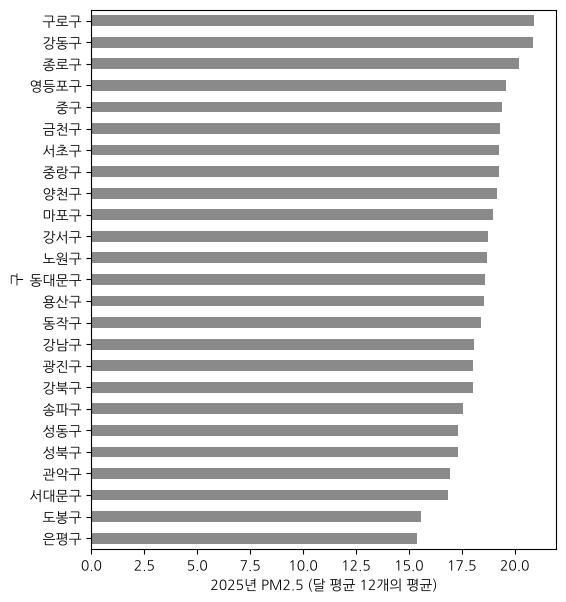

가장 낮은 구: 은평구 15.4 | 가장 높은 구: 구로구 20.9


In [26]:
gu = web.groupby("구")["PM25"].mean().sort_values()  # 작은 값부터
gu.plot.barh(color="#8a8a8a", figsize=(6, 7))  # 가로 막대
plt.xlabel("2025년 PM2.5 (달 평균 12개의 평균)"); plt.show()
print("가장 낮은 구:", gu.index[0], round(gu.iloc[0], 1), "| 가장 높은 구:", gu.index[-1], round(gu.iloc[-1], 1))

- 이름이 긴 항목 25개를 견줄 때는 가로 막대(`barh`)가 읽기 쉽고, `sort_values( )`로 줄 세우면 순위가 한눈에 보입니다.
- `gu.index[0]`, `gu.iloc[0]`: 줄 세운 결과의 첫째(가장 낮은) 구 이름과 값입니다. `[-1]`은 맨 끝입니다.


은평구가 가장 낮고 구로구가 가장 높지만 차이는 5.5 정도입니다. 빈칸이 있는 관악구와 금천구의 평균은 10달·11달의 평균이라는 점도 함께 적어 둡니다.

> **[분석 기법] 원본은 그대로, 과정은 코드로: 재현 가능한 분석**
>
> 웹에서 모은 300칸이 파일 길과 모두 같았다는 것은, 두 출처가 서로를 검증해 주었다는 뜻입니다. 이런 확인이 가능하려면 분석이 **재현 가능**해야 합니다. 같은 원본과 같은 코드로 누가 다시 돌려도 같은 결과가 나와야 합니다.
>
> 지킬 것은 세 가지입니다. ① **원본 파일은 고치지 않고** 받은 그대로 따로 보관합니다. 엑셀에서 손으로 지운 한 줄은 기록이 남지 않습니다. ② 지우기·바꾸기·합치기는 **모두 코드로** 하고, 노트북에 순서대로 남깁니다. ③ 웹 데이터는 **모은 날짜**를 적고, 모은 결과를 파일로 저장해 둡니다. 페이지는 내일 바뀔 수 있기 때문입니다. 머신러닝에서도 학습에 쓴 데이터와 코드를 그대로 보관해야 나중에 결과를 설명할 수 있습니다.

### [실습 예제 6-7 ☆] read_html 한 줄로 표 읽기 🧪 코랩 실습

> 책에는 이 실습의 문제만 실었습니다. 단계별 코드와 설명은 아래에 있습니다.

측정소 페이지 하나를 `pd.read_html( )`로 읽어, 6-6처럼 직접 파싱한 결과와 견주시오.

In [27]:
import io
html = requests.get(st["주소"][0], headers=HEAD).text
tables = pd.read_html(io.StringIO(html))  # 페이지 속 <table>을 모두 표로
print("표 개수:", len(tables))
print(tables[0].head(3).to_string())

표 개수: 1
         달  PM10 평균  PM2.5 평균  측정 시간
0  2025-01     40.0      30.0    729
1  2025-02     32.6      21.7    669
2  2025-03     46.2      31.5    737


- `pd.read_html( )`: HTML 속 `<table>`을 모두 찾아 데이터프레임의 **목록**으로 돌려줍니다. 표가 하나여도 목록이므로 `tables[0]`으로 꺼냅니다.
- `io.StringIO(html)`: 글자를 파일처럼 다루게 감쌉니다. 새 판다스는 HTML 글자를 바로 넣는 대신 이렇게 넣으라고 권합니다.

한 줄로 달·PM10·PM2.5·측정 시간 표가 읽혔습니다. 다만 칸 속 링크처럼 표 밖의 정보는 가져오지 못하고, 표가 `<table>`이 아닌 다른 태그로 그려진 페이지에서는 쓸 수 없습니다. 그럴 때는 6-5처럼 직접 파싱합니다.

### [실습 예제 6-8 ☆] 동적 페이지: 빈 칸 뒤의 JSON 찾기 🧪 코랩 실습

> 책에는 이 실습의 문제만 실었습니다. 단계별 코드와 설명은 아래에 있습니다.

측정소 페이지의 "날마다 PM2.5" 칸을 requests로 읽고, 그 칸이 부르는 JSON을 직접 받아 그리시오.


**❶ 빈 칸 확인하기**

In [28]:
s = get_soup(st["주소"][0])
box = s.find("div", id="daily")
print("파이썬이 받은 칸:", box.text)
print("칸이 부르는 자료:", box["data-src"])

파이썬이 받은 칸: 그래프를 불러오는 중입니다…
칸이 부르는 자료: ../api/daily_111121.json


그래프는 페이지가 열린 뒤 **자바스크립트**(웹페이지 안에서 도는 프로그램)가 JSON을 받아 그리므로, 파이썬이 받은 칸에는 안내 글만 있습니다. 이런 페이지를 **동적 페이지**라고 합니다. 칸의 `data-src` 속성에 자료의 주소가 적혀 있습니다(실제 사이트는 F12의 "네트워크" 탭에서 찾습니다).

**❷ JSON을 직접 받아 표로**

In [29]:
js = requests.get(urljoin(st["주소"][0], box["data-src"]), headers=HEAD).json()
print("JSON 열쇠:", list(js.keys()))
print(js["daily"][:2])
d = pd.DataFrame(js["daily"])
d["date"] = pd.to_datetime(d["date"])
print(d.shape, "| 가장 높은 날:", d.loc[d["pm25"].idxmax(), "date"].date(), d["pm25"].max())

JSON 열쇠: ['station', 'code', 'unit', 'daily']
[{'date': '2025-01-01', 'pm25': 20.8}, {'date': '2025-01-02', 'pm25': 19.2}]
(365, 2) | 가장 높은 날: 2025-01-21 111.6


- `.json( )`: 받은 JSON 글자를 파이썬의 사전과 목록으로 바꿉니다.
- `js["daily"]`: 사전 목록입니다. `pd.DataFrame( )`에 넣으면 사전 하나가 한 줄이 됩니다(6-5와 같은 방법).
- `idxmax( )`: 가장 큰 값이 있는 줄의 이름표입니다. `d.loc[그 줄, "date"]`로 그날을 꺼냅니다.

> **[잠깐만요] JSON과 파이썬 사전**
>
> JSON의 `{ }`는 파이썬의 사전, `[ ]`는 목록, `"글자"`는 글자, 숫자는 숫자, `true`·`false`·`null`은 `True`·`False`·`None`이 됩니다. 그래서 `.json( )` 한 번이면 바로 `js["daily"][0]["pm25"]`처럼 꺼낼 수 있습니다. 묶음이 여러 겹이면 `pd.json_normalize( )`가 안쪽 이름표를 펼쳐 열로 만들어 줍니다. 날씨·교통·주식 API 대부분이 JSON으로 답하므로 이 모양에 익숙해지면 좋습니다.

**❸ 그리기**

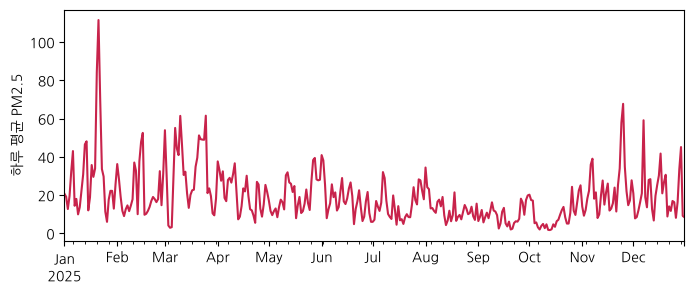

In [30]:
d.plot(x="date", y="pm25", color="#C8234B", legend=False, figsize=(8, 3))
plt.xlabel(""); plt.ylabel("하루 평균 PM2.5"); plt.show()

11월부터 3월 사이에 높은 날이 몰려 있고, 1월 21일이 111.6으로 가장 높습니다.

### [실습 예제 6-9 ☆] 저장 형식 견주기와 나누어 읽기 🧪 코랩 실습

> 책에는 이 실습의 문제만 실었습니다. 단계별 코드와 설명은 아래에 있습니다.

6-3의 표(350,400행)를 CSV, 파케이, 엑셀로 저장해 견주고, CSV를 10만 줄씩 나누어 읽으며 PM2.5가 75를 넘은 측정을 세시오.

**❶ 세 형식으로 저장하고 다시 읽기**

In [31]:
os.makedirs("저장", exist_ok=True)
keep = air.drop(columns=["파일", "달"])
for kind in ["csv", "parquet", "xlsx"]:
    path = "저장/서울_2025." + kind
    t0 = time.time()
    if kind == "csv": keep.to_csv(path, index=False)
    elif kind == "parquet": keep.to_parquet(path, index=False)
    else: keep.to_excel(path, index=False)
    t_w = time.time() - t0; t0 = time.time()
    back = {"csv": pd.read_csv, "parquet": pd.read_parquet, "xlsx": pd.read_excel}[kind](path)
    print(f"{kind:>7}: {os.path.getsize(path) / 1e6:5.1f} MB | 쓰기 {t_w:4.1f}초 | 읽기 {time.time() - t0:4.1f}초")

    csv:  46.7 MB | 쓰기  2.3초 | 읽기  0.6초


parquet:   2.4 MB | 쓰기  0.8초 | 읽기  0.1초


   xlsx:  17.3 MB | 쓰기 38.8초 | 읽기 27.2초


- `os.makedirs("저장", exist_ok=True)`: 폴더를 만들고, 이미 있으면 그냥 넘어갑니다.
- `index=False`: 줄 번호를 파일에 쓰지 않습니다. 쓰면 다시 읽을 때 "Unnamed: 0" 열이 생깁니다.
- `{…}[kind](path)`: 형식 이름으로 읽기 함수를 사전에서 골라 바로 부릅니다. 함수도 사전의 값이 될 수 있습니다.

파케이는 CSV의 약 20분의 1 크기로 가장 빨리 읽혔고, 엑셀은 쓰기와 읽기가 가장 느렸습니다(시간은 컴퓨터마다 다릅니다).

**❷ 10만 줄씩 나누어 읽기**

In [32]:
n_bad = 0
for chunk in pd.read_csv("저장/서울_2025.csv", chunksize=100_000):  # 10만 줄씩
    n_bad += (chunk["PM25"] > 75).sum()
print("PM2.5가 75를 넘은 측정:", n_bad, "번")

PM2.5가 75를 넘은 측정: 2879 번


- `chunksize=100_000`: 표 전체 대신 10만 줄짜리 조각을 차례로 건네줍니다. `100_000`의 밑줄은 읽기 쉽게 끊은 것일 뿐 100000과 같습니다.
- `(chunk["PM25"] > 75).sum()`: True를 1, False를 0으로 세어 조건에 맞는 줄 수를 냅니다. 조각마다 센 값을 `n_bad`에 더해 갑니다.

> **[분석 기법] 메모리보다 큰 데이터 다루기**
>
> 판다스는 표 전체를 컴퓨터의 **메모리**(작업대)에 올려놓고 계산합니다. 파일이 메모리보다 크면 읽다가 멈춥니다. 이때 쓰는 방법은 두 가지입니다. ① **나누어 읽기**: `read_csv(…, chunksize=100_000)`은 10만 줄씩 차례로 건네주므로, 조각마다 세거나 더한 값만 모읍니다. ② **필요한 열만 읽기**: `usecols=["측정일시", "PM25"]`처럼 열을 고르면 메모리가 크게 줍니다. 파케이는 열 단위로 저장하므로 고른 열만 빠르게 읽습니다.

### [실습 예제 6-10 ☆] 같아 보이는 이름, 다른 글자 🧪 코랩 실습

> 책에는 이 실습의 문제만 실었습니다. 단계별 코드와 설명은 아래에 있습니다.

"2025년 1월.xlsx"를 맥이 쓰는 모양(NFD)으로 바꾸어 견주고, 다시 보통 모양(NFC)으로 되돌리시오.

In [33]:
import unicodedata
name = "2025년 1월.xlsx"
mac = unicodedata.normalize("NFD", name)  # 맥에서 압축한 파일 이름의 모양
print(name == mac, len(name), len(mac))
print([hex(ord(c)) for c in mac[4:7]])
print("다시 합치면:", unicodedata.normalize("NFC", mac) == name)
server.terminate()  # 연습 사이트 끄기

False 13 17
['0x1102', '0x1167', '0x11ab']
다시 합치면: True


- `unicodedata.normalize("NFD", 글자)`: 한글 한 글자를 낱자(초성·중성·종성)로 풀어 씁니다. "년"이 세 글자가 되어 13글자가 17글자가 됩니다.
- `ord(c)`: 글자의 번호(유니코드), `hex( )`는 16진수입니다. `0x1102`(ㄴ)·`0x1167`(ㅕ)·`0x11ab`(ㄴ 받침)이 "년"을 이룹니다.
- `server.terminate( )`: 6-4에서 켠 연습 사이트를 끕니다.

화면에서는 같아 보여도 `==`가 False이므로, 3.1절처럼 "파일이 0개"가 됩니다. 맥에서 만든 압축 파일을 다룰 때는 파일 이름을 `normalize("NFC", …)`로 맞춘 뒤 찾습니다.

> **핵심 3줄**
>
> 파일 길은 "인코딩 확인 → 신원 확인 → 찾기·순서·합치기 → 검산"이고, 웹 길은 "robots.txt → 이름 밝힌 요청 → 파싱 → 쪽 넘기기"입니다.
>
> 요청은 쉬기·이름 밝히기·실패하면 멈추기를 묶은 함수 하나로 보내고, 숫자 칸의 글자는 `to_numeric(errors="coerce")`로 빈칸으로 바꿉니다.
>
> 같은 값을 두 길로 얻으면 서로 맞춰 봅니다(300칸 모두 같음).

## [미니 프로젝트 6] 5년 치 전력수요 파일을 한 표로

**질문.** 한국전력거래소는 전국 전력수요를 한 해에 파일 하나씩 공개합니다. 다섯 해 치를 한 표로 모으면, 해마다 전기를 가장 많이 쓴 때는 언제였을까요?

**데이터.** 공공데이터포털의 "한국전력거래소 시간별 전국 전력수요량" CSV 5개(2021~2025년)¹¹⁾입니다. 강의 자료의 「전력수요」 폴더에 받은 그대로 들어 있습니다. 한 행이 하루이고, 열은 날짜와 1시~24시의 수요(MW) 25개입니다. 인코딩은 CP949입니다.

**🧪 1단계: 신원 확인**([실습 예제 6-1, 6-2] 응용). 2021년 파일을 읽고 크기, 첫 두 행, 자료형을 확인하시오.  *(코랩 실습: 책에는 결과만)*

In [34]:
P = DATA + "/전력수요/한국전력거래소_시간별_전국_전력수요량_2021.csv"
y21 = pd.read_csv(P, encoding="cp949")
print(y21.shape)
print(y21.iloc[:2, :6].to_string())
print(y21.dtypes.value_counts().to_dict())

(365, 25)
           날짜     1시     2시     3시     4시     5시
0  2021-01-01  64942  62593  60905  59889  59638
1  2021-01-02  60658  58603  57309  56663  56733
{dtype('int64'): 24, <StringDtype(na_value=nan)>: 1}


- `encoding="cp949"`: 공공기관 CSV라 CP949부터 시도합니다(6-1의 순서).
- `y21.iloc[:2, :6]`: 처음 두 줄, 처음 여섯 열입니다. 25열을 다 찍지 않고 모양만 봅니다.
- `dtypes.value_counts( )`: 자료형마다 열이 몇 개인지 셉니다. 수요 24열은 정수, 날짜 1열은 글자입니다.

365행 25열, 하루가 한 줄이고 24개 시각이 열로 나란히 있는 **넓은 표**입니다. 날짜가 아직 글자이므로 3단계에서 날짜로 바꿉니다.

**🧪 2단계: 다섯 파일 합치고 검산하기**([실습 예제 6-3] 응용). 행 수와 열 이름을 확인하고 합친 뒤, 날짜가 빈 행, 같은 날짜, 빈칸을 세시오.  *(코랩 실습: 책에는 결과만)*

In [35]:
files = sorted(glob.glob(DATA + "/전력수요/*.csv"))
parts = [pd.read_csv(f, encoding="cp949") for f in files]
print([len(p) for p in parts])
print("열이 모두 같은가:", all(list(p.columns) == list(parts[0].columns) for p in parts))
kpx = pd.concat(parts, ignore_index=True)
print("합친 크기:", kpx.shape, "| 날짜가 빈 행:", kpx["날짜"].isna().sum())
print(kpx[kpx["날짜"].isna()].iloc[:, :4].to_string())

[365, 365, 365, 366, 366]
열이 모두 같은가: True
합친 크기: (1827, 25) | 날짜가 빈 행: 1
       날짜  1시  2시  3시
1826  NaN NaN NaN NaN


파일별 행 수는 365, 365, 365, 366, 366입니다. 2024년은 윤년이라 366이 맞지만, 2025년도 366입니다. 날짜가 빈 행 하나가 그 까닭입니다. 2025년 파일 끝에 쉼표만 있는 빈 줄이 붙어 있던 것입니다. 파일 이름에 연도가 들어 있어 글자 순서(`sorted`)가 곧 연도 순서이므로, 이번에는 `key=`가 필요 없습니다.

In [36]:
kpx = kpx.dropna(subset=["날짜"])  # 날짜가 빈 줄 지우기
kpx = kpx.astype({c: "int64" for c in kpx.columns[1:]})  # 빈 줄 때문에 소수가 된 열을 정수로
print("지운 뒤:", kpx.shape, "| 같은 날짜:", kpx["날짜"].duplicated().sum(), "| 빈칸:", kpx.isna().sum().sum())

지운 뒤: (1826, 25) | 같은 날짜: 0 | 빈칸: 0


- `dropna(subset=["날짜"])`: 날짜 열이 빈 줄만 지웁니다. `subset` 없이 쓰면 어느 칸이든 빈 줄을 모두 지워 버립니다.
- `astype({…})`: 빈 줄의 NaN 때문에 소수(`float64`)로 바뀌었던 수요 열을 다시 정수로 돌립니다. `{c: "int64" for c in …}`은 사전을 한 줄로 만드는 컴프리헨션입니다.
- `duplicated( ).sum( )`: 앞에 이미 나온 날짜가 몇 번 다시 나오는지 셉니다. 0이면 겹친 날이 없습니다.

1,826일(365 × 4 + 1)이 되었고, 겹친 날도 빈칸도 없습니다.

**3단계: 넓은 표를 긴 표로.** `melt( )`로 한 시간이 한 줄인 표를 만들고, 날짜와 시로 일시를 만드시오(시가 1~24이므로 [실습 예제 6-2]처럼).

In [37]:
long = kpx.melt(id_vars="날짜", var_name="시", value_name="수요")  # 넓은 표 → 긴 표
long["시"] = long["시"].str.replace("시", "").astype(int)  # "13시" → 13
long["일시"] = pd.to_datetime(long["날짜"]) + pd.to_timedelta(long["시"], unit="h")
long = long.sort_values("일시").reset_index(drop=True)
print(long.shape)
print(long.head(3).to_string())
print("시간 간격:", long["일시"].diff().value_counts().to_dict())

(43824, 4)
           날짜  시     수요                  일시
0  2021-01-01  1  64942 2021-01-01 01:00:00
1  2021-01-01  2  62593 2021-01-01 02:00:00
2  2021-01-01  3  60905 2021-01-01 03:00:00
시간 간격: {Timedelta('0 days 01:00:00'): 43823}


- `melt(id_vars="날짜", …)`: 날짜는 그대로 두고, 나머지 24열을 "시"와 "수요" 두 열로 녹입니다.
- `.str.replace("시", "")`: 글자 열 전체에서 "시"를 지웁니다. `.str`은 "열의 글자마다"라는 뜻입니다.
- 일시: 날짜(0시) + 시간 길이이므로 24시는 다음 날 0시가 됩니다(6-2와 같은 방법).
- `diff( )`: 이웃한 두 줄의 차이입니다. 모든 간격이 한 시간이면 빠지거나 겹친 시각이 없다는 뜻입니다.

> **[잠깐만요] 넓은 표와 긴 표, 그리고 melt**
>
> **넓은 표**는 대상 하나가 한 줄이고 측정값이 옆으로 늘어선 모양입니다(학생 한 명이 한 줄, 국어·영어·수학이 열). 사람이 보기에 편합니다. **긴 표**는 측정값 하나가 한 줄입니다(학생, 과목, 점수의 세 열). 그래프를 그리고 묶어 세기(groupby)에 편합니다. `melt(id_vars="학생", var_name="과목", value_name="점수")`는 넓은 표를 긴 표로, `pivot_table( )`은 그 반대로 바꿉니다. 행 수는 "원래 줄 수 × 녹인 열 수"가 되어야 합니다. 여기서는 1,826일 × 24시간 = 43,824줄입니다.

43,824줄이고, 이웃한 두 줄의 간격 43,823개가 모두 정확히 한 시간입니다. 빠진 시각도 겹친 시각도 없습니다.

**4단계: 답하기.** 해마다 수요가 가장 컸던 날과 시를 찾고, 해마다 시각별 평균 수요를 한 그림에 그리시오.

In [38]:
top = long.loc[long.groupby(long["날짜"].str[:4])["수요"].idxmax(), ["날짜", "시", "수요"]]
print(top.to_string(index=False))

        날짜  시    수요
2021-07-27 18 91141
2022-12-23 11 94509
2023-08-07 17 93615
2024-08-20 17 97115
2025-08-25 18 95951


- `long["날짜"].str[:4]`: 날짜 글자의 앞 네 자리, 곧 연도입니다.
- `groupby(연도)["수요"].idxmax( )`: 해마다 수요가 가장 큰 줄의 번호입니다. `long.loc[그 번호들, 열들]`로 그 줄들을 꺼냅니다.

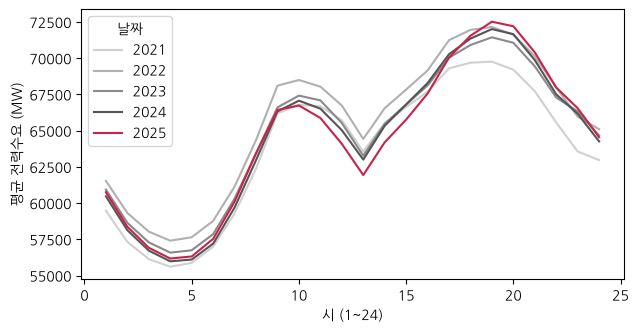

In [39]:
prof = long.pivot_table(index="시", columns=long["날짜"].str[:4], values="수요", aggfunc="mean")
prof.plot(figsize=(7, 3.5), color=["#d0d0d0", "#b0b0b0", "#8a8a8a", "#555555", "#C8234B"])
plt.xlabel("시 (1~24)"); plt.ylabel("평균 전력수요 (MW)"); plt.show()

- `pivot_table`: 긴 표를 다시 넓은 표로 바꾸며 평균을 냅니다. 행은 시(1~24), 열은 연도, 값은 그 시각의 평균 수요입니다.
- 넓은 표에 `.plot( )`을 하면 열(연도)마다 선이 하나씩 그려집니다. 2025년만 진홍으로 칠해 눈에 띄게 했습니다.


네 해는 여름 17~18시가 최대였고 2022년만 겨울(12월 23일 11시)이었습니다. 하루 안에서는 오전 10시와 저녁 19시 무렵 두 번 높아지고, 낮 13시에 한 번 내려갑니다.

**5단계: 한계 쓰기.** 모르는 것을 [표 6-1]처럼 쓰되, "이 수요에 빠진 것"(예: 전력시장을 거치지 않는 자가용 태양광)을 반드시 다루시오.

예를 들면 "2025년 낮 12~15시 수요가 가장 낮다"는 관찰은 쓸 수 있지만, "태양광이 늘어서"라고 단정할 수는 없습니다. 이 자료에는 지붕 위 태양광처럼 전력시장을 거치지 않고 쓰인 전기가 빠져 있기 때문입니다. 원인을 말하려면 날씨와 설비 자료를 함께 봐야 합니다.

**제출물.** 그림 2장, 표 1개(해마다 최대 수요의 날짜·시·값), 결론 5문장 이내.

**[표 6-2] 미니 프로젝트 채점 기준**

| 항목(비중) | 상 | 중 | 하 |
|---|---|---|---|
| 데이터 점검(20%) | 인코딩·열 이름·행 수·빈 줄 모두 확인 | 빈 줄만 지움 | 확인 없이 합침 |
| 검산(20%) | 43,824줄과 한 시간 간격 검산 | 행 수만 셈 | 검산 안 함 |
| 기법 적용(30%) | 찾기·합치기·melt·24시 처리가 맞음 | 파일 이름을 손으로 적음 | 코드가 돌지 않음 |
| 해석과 한계(30%) | 최대 수요를 바르게 읽고 빠진 것을 씀 | 한계를 한두 가지 씀 | 원인을 단정함 |

## ✏️ 연습문제

책의 연습문제입니다. 먼저 풀어 본 뒤 정답을 펼쳐 보십시오.

### [연습문제 6-1] 바이트 세기

"데이터"와 "AI"를 UTF-8과 CP949로 저장하면 각각 몇 바이트인지 (식 6-1)로 구하시오.

<details><summary>정답</summary>

"데이터"는 UTF-8로 3 × 3 = 9바이트, CP949로 3 × 2 = 6바이트, "AI"는 두 약속 모두 2바이트입니다.

</details>

### [연습문제 6-2] 24시 바꾸기

측정일시 2025013124를 몫과 나머지로 나누고, 실제 시각으로 바꾸는 코드를 쓰시오.

<details><summary>정답</summary>

`2025013124 // 100`은 20250131(날짜), `2025013124 % 100`은 24(시)입니다. `pd.to_datetime("20250131", format="%Y%m%d") + pd.to_timedelta(24, unit="h")`는 2025-02-01 00:00:00입니다.

</details>

### [연습문제 6-3] 기대 행 수

서울 측정소 40곳이 한 시간에 한 줄씩 남긴다면 2024년 2월 파일은 몇 줄이어야 하는지 (식 6-5)로 구하시오.

<details><summary>정답</summary>

2024년은 윤년이라 2월이 29일입니다. 40 × 29 × 24 = 27,840줄입니다. 실제 2024년 2월 원본에서 서울 행을 세어 보니 27,840줄로 같았습니다. 2월을 28일로 계산하면 960줄이 모자란다고 잘못 판단하게 됩니다.

</details>

### [연습문제 6-4] 상태 코드 읽기

다음 세 경우에 받을 상태 코드를 쓰고, 무엇을 고쳐야 하는지 답하시오. (가) 주소의 쪽 번호를 잘못 적었다. (나) User-Agent 없이 요청했더니 사이트가 거절했다. (다) 페이지를 잘 받았다.

<details><summary>정답</summary>

(가) 404: 주소를 다시 확인합니다. (나) 403: User-Agent에 이름과 목적을 적고, 그래도 거절되면 파일이나 API를 찾습니다(브라우저인 척 속이지 않음). (다) 200: 원하는 내용이 실제로 있는지 확인합니다(동적 페이지는 비어 있을 수 있음).

</details>

### [연습문제 6-5] robots.txt 읽기

어떤 사이트의 robots.txt가 다음과 같습니다. (가) `data-class-bot`은 /news/ 페이지를 가져가도 되는가? (나) GPTBot은? (다) 우리 로봇은 요청 사이에 몇 초를 쉬어야 하는가?

```text
User-agent: GPTBot
Disallow: /

User-agent: *
Disallow: /search/
Crawl-delay: 2
```

<details><summary>정답</summary>

(가) 됩니다(*에게는 /search/만 막힘). (나) 안 됩니다(전체가 막힘). (다) 2초.

</details>

### [연습문제 6-6] 뷰티풀수프로 찾기

다음 HTML에서 (가) 첫 기사 제목, (나) 모든 링크 주소의 목록, (다) 날짜를 꺼내는 코드를 쓰시오.

```text
<ul class="news">
  <li><a href="/a1">첫 기사</a></li>
  <li><a href="/a2">둘째 기사</a></li>
</ul>
<p class="date">2025-10-20</p>
```

<details><summary>정답</summary>

(가) `s.find("li").text` → 첫 기사, (나) `[a["href"] for a in s.find_all("a")]` → ['/a1', '/a2'], (다) `s.find("p", class_="date").text` → 2025-10-20.

</details>

### [연습문제 6-7] 수집하기 전에

뉴스 사이트에서 기사 제목을 매일 모으는 프로그램을 만들려고 합니다. 코드를 쓰기 전에 확인할 것 네 가지를 쓰고, 각각 왜 필요한지 답하시오.

<details><summary>정답</summary>

① 같은 자료를 API나 파일로 주는지: 화면 구조가 바뀌어도 멈추지 않고, 사이트에 부담도 적습니다. ② robots.txt: 사이트가 로봇에게 허락한 경로인지 확인합니다. ③ 이용약관과 저작권: 기사 본문은 저작물이므로 제목·주소처럼 필요한 만큼만 모으고, 공개·재배포는 따로 허락을 받아야 합니다. ④ 요청 간격과 User-Agent: 사이트에 부담을 주지 않고, 문제가 생기면 사이트가 연락할 수 있게 누구인지 밝힙니다.

## 각주

1) M. Koster, "A Standard for Robot Exclusion" (1994). 코스터는 1994년 2월 www-talk 메일링 리스트에 이 약속을 처음 제안했습니다. 작가 찰스 스트로스는 자신이 만든 로봇이 코스터의 서버를 멈추게 한 일이 계기였다고 밝힌 바 있습니다.
2) M. Koster, G. Illyes, H. Zeller, L. Sassman, "Robots Exclusion Protocol", RFC 9309, IETF (2022.9).
3) 한국전력거래소, "2024년 연료원별 시간대별 설비용량 및 전력거래량"(엑셀). 시트의 1~4행이 안내문, 5행이 빈 줄, 6행이 열 이름입니다.
4) 한국환경공단 에어코리아(airkorea.or.kr), 최종확정 측정자료(월별 엑셀). 공공누리 제1유형(출처표시) 조건으로 씁니다.
5) 기상청 기상자료개방포털(data.kma.go.kr), 종관기상관측(ASOS) 시간자료, 서울(108). 이 장의 파일은 2026년 10월 16일 1시부터 24시간 치를 받은 원본 그대로입니다.
6) S. Brin, L. Page, "The Anatomy of a Large-Scale Hypertextual Web Search Engine", Computer Networks and ISDN Systems, 30(1–7) (1998).
7) Common Crawl, https://commoncrawl.org. 2008년부터 크롤링 자료를 공개해 왔습니다.
8) T. Brown 외, "Language Models are Few-Shot Learners", NeurIPS (2020). 표 2.2에 학습 데이터의 출처와 비율이 있습니다.
9) OpenAI 개발자 문서 "GPTBot"(2023년 8월 공개). 크롤러의 User-Agent 이름과 robots.txt로 막는 방법을 설명합니다.
10) Reuters Institute for the Study of Journalism, "How many news websites block AI crawlers?" (2024.2).
11) 공공데이터포털(data.go.kr), "한국전력거래소_시간별 전국 전력수요량". 공공누리 출처표시 조건으로 씁니다.

</details>

In [40]:
# 여기에 직접 코드를 써 보십시오.